# GG4257 - Creating Sustainable Cities with Spatial Data Science
## Lab 5 Challenge 7
All code cells will include a brief explanation of that code line unless included in lab, in cases where I have used websites or documentation, please refer to the [x] section of the 'references' cell at the end of the notebook to view citations.
### 220016532

### Landon Evans
#### Student ID : _220016532_
#### Github : _land0nevans_
#### URL : https://github.com/land0nevans/UA-Lab2

In [1]:
import os
import math
import getpass
import requests
import pandas as pd
import geopandas as gpd
import networkx as nx
import osmnx as ox
import matplotlib.pyplot as plt
from shapely.ops import unary_union
import overturemaps


I attempted to run the code below, but kept getting a timeout error. I have included the code below which I *think* would have worked, but I opted to use the provided gpkg files from moodle.
```python
CITY = "De Pijp, Amsterdam" 
G_city = ox.graph_from_point((52.3540, 4.8930), dist=2000, network_type="walk") # changed this line as suggested in challenge 6.
G_city = ox.project_graph(G_city).to_undirected()
crs = G_city.graph["crs"]
parks = ox.features_from_point((52.3540, 4.8930), tags={"leisure": "park"}).to_crs(crs) # also edited this line to use features_from_point
parks = parks[parks.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
parks["area_m2"] = parks.area
buildings = ox.features_from_point((52.3540, 4.8930), tags={"building": True}).to_crs(crs)
```


#### Part 1 : Data

In [2]:
G_city = ox.load_graphml("challenge_data/amsterdam_walk.graphml") # opted to import provided files, similar to dundee example in lab
G_city = ox.project_graph(G_city).to_undirected() 
crs = "EPSG:28992" # had to project to amsterdam's local crs, as i kept getting errors
parks = gpd.read_file("challenge_data/amsterdam_parks.gpkg").to_crs(crs) 
parks = parks[parks.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
parks["area_m2"] = parks.area
buildings = gpd.read_file("challenge_data/amsterdam_buildings.gpkg").to_crs(crs)

In [3]:
#buildings.explore()

In [4]:
DEPIJP_BOX = (4.876213,52.338695,4.920244,52.364280)        # de pijp boundary box

table = overturemaps.record_batch_reader("place", bbox=DEPIJP_BOX, stac=True).read_all() # downloads overture places
places = table.to_pandas()
places["geometry"] = gpd.GeoSeries.from_wkb(places["geometry"])
places = gpd.GeoDataFrame(places, geometry="geometry", crs="EPSG:4326").to_crs("EPSG:28992") # had to convert crs
places["name"] = places["names"].str.get("primary")      # each place can have several names; keep the main one

print(len(places), "Overture places in De Pijp")

11825 Overture places in De Pijp


In [5]:
pharmacy_depijp = places["basic_category"].str.contains("pharmacy|drug", na=False)
pharmacy_depijp = places[pharmacy_depijp & (places["confidence"] >= 0.5)].copy()

hospital_depijp = places["basic_category"].str.contains("hospital", na=False)
hospital_depijp = places[hospital_depijp & (places["confidence"] >= 0.5)].copy()

print(pharmacy_depijp["basic_category"].value_counts())
print(hospital_depijp["basic_category"].value_counts())
print()
print("Pharmacies in Overture:     ", len(pharmacy_depijp))
print("Hospitals in Overture:     ", len(hospital_depijp))

basic_category
pharmacy_and_drug_store    46
Name: count, dtype: int64
basic_category
hospital              19
specialty_hospital     1
Name: count, dtype: int64

Pharmacies in Overture:      46
Hospitals in Overture:      20


#### Part 2 : Isochrones

In [6]:
DEPIJP = (52.3540, 4.8930)       # changed to de pijp
AREA = 1200                      
WALK_LIMIT = 1200                  # 15 minutes walking
WALK_SPEED = 80     
SERVICES = {
    "School":           {"amenity": "school"},
    "Food shop":        {"shop": ["supermarket", "convenience", "greengrocer"]},
    "Healthcare":       {"amenity": ["doctors", "clinic", "pharmacy", "hospital"]},
    "Park":             {"leisure": "park"},
    "Public transport": {"highway": "bus_stop", "railway": "station"},
}

In [7]:
G_walk = ox.load_graphml("challenge_data/amsterdam_walk.graphml")
G_walk = ox.project_graph(G_walk, to_crs="EPSG:28992").to_undirected()

print("Walk network:", len(G_walk), "Junctions")

Walk network: 7985 Junctions


In [8]:
walk_nodes, walk_edges = ox.graph_to_gdfs(G_walk)

centre = gpd.GeoSeries.from_xy([DEPIJP[1]], [DEPIJP[0]], crs="EPSG:4326").to_crs("EPSG:28992")
neighbourhood = centre.buffer(AREA).iloc[0]

distance = walk_nodes[walk_nodes.within(neighbourhood)].copy() # sets 800m distance using AREA, i removed residential part of code as i did not have this file

In [9]:
#services = gpd.read_file("challenge_data/amsterdam_overture_places.gpkg").to_crs("EPSG:28992")

In [10]:
def isochrone(G, start_node, metres):
    reachable = nx.ego_graph(G, start_node, radius=metres, distance="length")
    streets = ox.graph_to_gdfs(reachable, nodes=False)
    return unary_union(list(streets.buffer(50)))

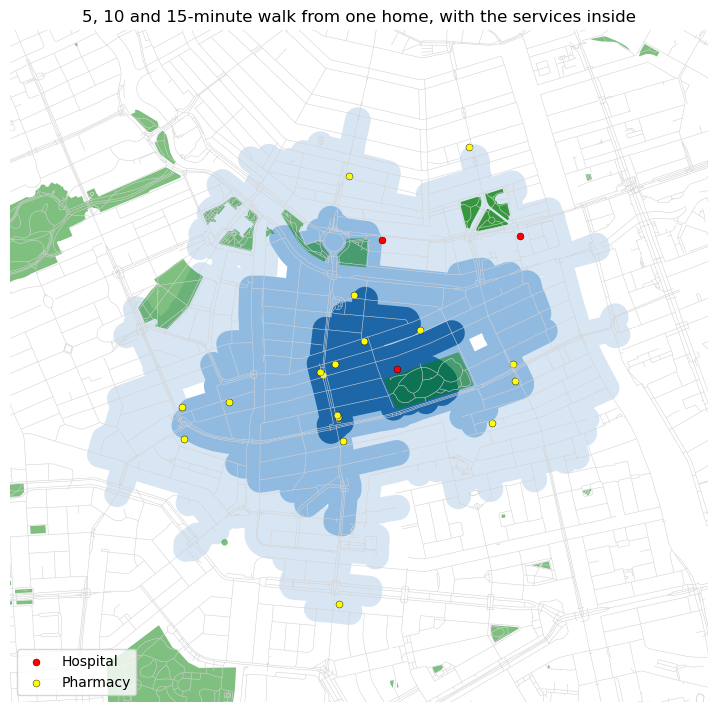

service
Pharmacy    18
Hospital     3
Name: count, dtype: int64


In [11]:
home = ox.distance.nearest_nodes(G_walk, centre.x.iloc[0], centre.y.iloc[0])   # the junction nearest the centre

fig, ax = plt.subplots(figsize=(9, 9))
walk_edges.plot(ax=ax, color="lightgrey", linewidth=0.4)
for minutes, colour in [(15, "#cfe0f0"), (10, "#7fb0dd"), (5, "#00539B")]:
    shape = isochrone(G_walk, home, minutes * WALK_SPEED)
    gpd.GeoSeries([shape], crs="EPSG:28992").plot(ax=ax, color=colour, alpha=0.8) # changed crs

iso15 = isochrone(G_walk, home, 15 * WALK_SPEED)

# i had issues running the graph code from lab to filter services by iso15, and i realised i had to make this using pd.concat 

hospital_depijp["service"]= "Hospital"
pharmacy_depijp["service"]= "Pharmacy"
services = pd.concat([hospital_depijp, pharmacy_depijp])
SERVICES = ["Hospital", "Pharmacy"]

inside = services[services.within(iso15)]
for name, colour in zip(SERVICES, ["red", "yellow"]): # changed colours for visibilty
    inside[inside["service"] == name].plot(ax=ax, color=colour, markersize=25, label=name, edgecolor="black", linewidth=0.3)

parks.plot(ax=ax, color="green", alpha=0.5)


ax.legend(loc="lower left")
ax.set_xlim(iso15.bounds[0] - 300, iso15.bounds[2] + 300)
ax.set_ylim(iso15.bounds[1] - 300, iso15.bounds[3] + 300)
ax.set_title("5, 10 and 15-minute walk from one home, with the services inside")
ax.set_axis_off()
plt.show()

print(inside["service"].value_counts())

#### Part 3 : 2SFCA

In [23]:
CITY = "De Pijp"
CATCHMENT = 800                 

G_city = ox.load_graphml("challenge_data/amsterdam_walk.graphml")
G_city = ox.project_graph(G_city, to_crs="EPSG:28992").to_undirected()        # i had to manually set the projection to amsterdam's
crs = G_city.graph["crs"]

parks = gpd.read_file("challenge_data/amsterdam_parks.gpkg").to_crs(crs)
parks["area_m2"] = parks.area

buildings = gpd.read_file("challenge_data/amsterdam_buildings.gpkg").to_crs(crs)
print(len(parks), "parks and", len(buildings), "buildings in", CITY)

69 parks and 35792 buildings in De Pijp


In [24]:
parks["node"] = ox.distance.nearest_nodes(G_city, parks.representative_point().x, parks.representative_point().y)
buildings["node"] = ox.distance.nearest_nodes(G_city, buildings.representative_point().x, buildings.representative_point().y)

demand = buildings["node"].value_counts()        # junction -> number of buildings
#demand.head()

In [25]:
reach = {}          # which junctions can walk to each park
ratio = {}          # park area divided by the buildings that can reach it

for park_id, park in parks.iterrows():
    nearby = nx.single_source_dijkstra_path_length(G_city, park["node"], cutoff=CATCHMENT, weight="length")
    buildings_nearby = sum(demand.get(node, 0) for node in nearby)
    reach[park_id] = nearby
    ratio[park_id] = park["area_m2"] / buildings_nearby if buildings_nearby > 0 else 0

parks["m2_per_building"] = pd.Series(ratio)
#parks.sort_values("m2_per_building", ascending=False)[["name", "area_m2", "m2_per_building"]].head(10).round(0)

In [26]:
city_nodes, city_edges = ox.graph_to_gdfs(G_city)
park_access = {node: 0.0 for node in G_city.nodes}

for park_id, nearby in reach.items():
    for node in nearby:
        park_access[node] += ratio[park_id]

city_nodes["park_access"] = pd.Series(park_access)

homes_city = city_nodes[city_nodes.index.isin(demand.index)]       # junctions that have buildings
#homes_city["park_access"].describe().round(0)

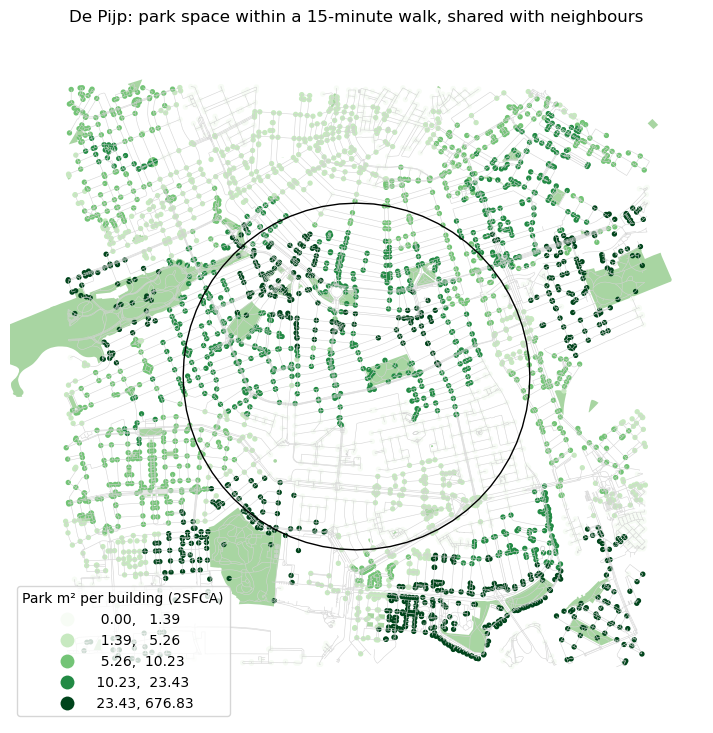

5% of homes have no park within a 15-minute walk


In [27]:
fig, ax = plt.subplots(figsize=(9, 9))
city_edges.plot(ax=ax, color="lightgrey", linewidth=0.4)
parks.plot(ax=ax, color="#a8d5a2")
homes_city.sort_values("park_access").plot(ax=ax, column="park_access", cmap="Greens", scheme="quantiles", k=5,
                                           markersize=8, legend=True,
                                           legend_kwds={"title": "Park m² per building (2SFCA)", "loc": "lower left"})

gpd.GeoSeries([neighbourhood], crs="EPSG:28992").boundary.plot(ax=ax, color="black", linewidth=1)
west, south, east, north = neighbourhood.buffer(WALK_LIMIT).bounds       # zoom to the neighbourhood (CHANGE TO JUST BOUNDS FOR 800M ASK LECTURER)
ax.set_xlim(west, east)
ax.set_ylim(south, north)

ax.set_title(f"{CITY}: park space within a 15-minute walk, shared with neighbours")
ax.set_axis_off()
plt.show()

print(f"{(homes_city['park_access'] == 0).mean():.0%} of homes have no park within a 15-minute walk")

#### Part 4 : Summary Table

In [28]:
print("Parks:", len(parks))
print("Buildings:", len(buildings))
print("Homes:", len(homes_city))
print("Pharmacies:", pharmacy_depijp.to_crs("EPSG:28992").within(iso15).sum())
print("Hospitals:", hospital_depijp.to_crs("EPSG:28992").within(iso15).sum())
print("Median park m2 per building:", homes_city["park_access"].median())
print(f"% of homes with no park within a 15-minute walk:{(homes_city['park_access'] == 0).mean():.0%}")

Parks: 69
Buildings: 35792
Homes: 3692
Pharmacies: 18
Hospitals: 3
Median park m2 per building: 7.4776139153505845
% of homes with no park within a 15-minute walk:5%


#### Part 5 : Conclusions

Regarding pharmacies and hospitals, De Pijp can be considered a 15 minute neighborhood, as there are 18 pharmacies and 3 hospitals within a 15 minute walk, and several pharmacies within the centre, in a 5 minute walk. From the 2SFCA, 5% of homes within a 800m catchment do not have access to a park within a 15 minute walk, with an average of 7.48m2 of median park space per building.

A key limitation is that I did not have access to a residential or homes file, so had to use the buildings file provided as part of the provided moodle, so results may be misconstrued. In order to determine whether this is a 15 minute neighborhood in terms of all services, more services other than pharmacies and hospitals would need to be included and displayed in the isochrone step.